# Flickr30k T3→S3 Held-out Test (một lần duy nhất)

Notebook này mở **Flickr30k Held-out Test đúng một lần** cho checkpoint đã
được khóa trước khi đọc Test:

- cặp: T3 SigLIP ViT-B/16 → S3 TinyViT-5M;
- phương pháp: Direct Logit-KD;
- checkpoint triển khai: seed 42, epoch 10;
- checkpoint SHA-256:
  `862f16b5b08bf580eac13ac112d529e9beeac7b8420116c598210f5b2c3ea4b4`;
- giải mã: Beam-3, length penalty 0,7;
- đầu ra metric hiển thị theo thang ×100, làm tròn hai chữ số.

**Không được dùng kết quả notebook này để huấn luyện lại, chọn lại
checkpoint, đổi ngưỡng hoặc đổi phương pháp.**

## Kaggle input bắt buộc — đúng 6 input

1. Output `F30K_Global_Val_Lock`;
2. Output `F30K_Data`;
3. Output `F30K_T3S3_LogitKD_42`;
4. Dataset `Flickr Image dataset`;
5. Dataset `Karpathy splits for Image Captioning`
   (phải có `dataset_flickr30k.json`);
6. package/dataset `pycocoevalcap-1.2` offline.

Runtime: **GPU T4**, Internet Off. Dự kiến 10–25 phút. Chỉ `Save Version`
một lần sau khi đã gắn đúng input.


## Cell 1 — Khóa quyền Test, SHA-256 và nguồn dữ liệu


In [1]:
import csv
import hashlib
import importlib.util
import json
import os
import random
import re
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

EXPERIMENT_ID = "F30K_T3S3_HeldOut_Test_OneTime"
INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working") / EXPERIMENT_ID
WORK_ROOT.mkdir(parents=True, exist_ok=True)
SEED = 42
EXPECTED_CHECKPOINT_SHA = "862f16b5b08bf580eac13ac112d529e9beeac7b8420116c598210f5b2c3ea4b4"
EXPECTED_ANNOTATION_SHA = "db779ee2c5df40c25ff0eebeca464f6124b620cc4a9398650aea71fd1b53d4af"

def now_utc():
    return datetime.now(timezone.utc).isoformat()

def sha256(path, chunk=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, payload):
    Path(path).write_text(
        json.dumps(payload, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )

def unique_named(name):
    matches = sorted(INPUT_ROOT.rglob(name))
    assert len(matches) == 1, (f"Cần đúng một {name}", matches)
    return matches[0]

GLOBAL_LOCK_PATH = unique_named("F30K_GLOBAL_VALIDATION_LOCK.json")
DATA_CONTRACT_PATH = unique_named("F30K_DATA_CONTRACT.json")
TEST_SEALED_PATH = unique_named("f30k_test_sealed.parquet")
VOCAB_PATH = unique_named("f30k_vocabulary_minfreq5.json")
ANNOTATION_PATH = unique_named("dataset_flickr30k.json")
KD_RESULT_PATH = unique_named("F30K_T3S3_LogitKD_42_RESULT.json")
CHECKPOINT_PATH = KD_RESULT_PATH.parent / "best.pt"

global_lock = json.loads(GLOBAL_LOCK_PATH.read_text(encoding="utf-8"))
contract = json.loads(DATA_CONTRACT_PATH.read_text(encoding="utf-8"))
kd_result = json.loads(KD_RESULT_PATH.read_text(encoding="utf-8"))
vocab = json.loads(VOCAB_PATH.read_text(encoding="utf-8"))

selected = global_lock["selected_method"]
assert global_lock["status"] == "locked"
assert global_lock["held_out_test_authorized"] is True
assert global_lock["held_out_test_authorization_count"] == 1
assert global_lock["test_set_used"] is False
assert global_lock["next_phase_authorized"] == EXPERIMENT_ID
assert selected["pair_id"] == "T3S3_LogitKD"
assert selected["method"] == "Direct Logit-KD"
assert int(selected["deployment_seed"]) == SEED
assert selected["deployment_experiment_id"] == kd_result["experiment_id"]
assert selected["deployment_checkpoint_sha256"] == EXPECTED_CHECKPOINT_SHA
assert CHECKPOINT_PATH.is_file()
assert sha256(CHECKPOINT_PATH) == EXPECTED_CHECKPOINT_SHA
assert CHECKPOINT_PATH.stat().st_size == int(selected["deployment_checkpoint_bytes"])

assert contract["dataset"] == "Flickr30k"
assert contract["test_set_status"] == "sealed"
assert contract["test_caption_exported"] is False
assert contract["test_image_count"] == 1000
assert sha256(TEST_SEALED_PATH) == contract["artifacts"]["test_sealed"]["sha256"]
assert sha256(VOCAB_PATH) == contract["vocabulary_sha256"]
assert sha256(ANNOTATION_PATH) == EXPECTED_ANNOTATION_SHA == contract["annotation_sha256"]
assert len(vocab["tokens"]) == 7456

if importlib.util.find_spec("pycocoevalcap") is None:
    wheels = sorted(INPUT_ROOT.rglob("pycocoevalcap*.whl"))
    if wheels:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", str(wheels[0])]
        )
    else:
        packages = [p for p in INPUT_ROOT.rglob("pycocoevalcap") if p.is_dir()]
        assert packages, "Hãy gắn input pycocoevalcap-1.2 offline."
        sys.path.insert(0, str(packages[0].parent))

assert importlib.util.find_spec("pycocoevalcap") is not None
assert shutil.which("java"), "METEOR chính thức yêu cầu Java runtime."
assert torch.cuda.is_available(), "Notebook Held-out Test yêu cầu GPU T4."
DEVICE = torch.device("cuda")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print("Authorization          : PASSED — ONE TIME")
print("Selected method        :", selected["pair_id"], "/", selected["method"])
print("Deployment seed/epoch  :", SEED, "/", selected["deployment_best_epoch"])
print("Checkpoint SHA-256     :", EXPECTED_CHECKPOINT_SHA)
print("Test images authorized :", contract["test_image_count"])
print("Method changes allowed : False")


Authorization          : PASSED — ONE TIME
Selected method        : T3S3_LogitKD / Direct Logit-KD
Deployment seed/epoch  : 42 / 10
Checkpoint SHA-256     : 862f16b5b08bf580eac13ac112d529e9beeac7b8420116c598210f5b2c3ea4b4
Test images authorized : 1000
Method changes allowed : False


## Cell 2 — Mở Test một lần, khóa reference và ảnh


In [2]:
test_sealed = pd.read_parquet(TEST_SEALED_PATH)
assert len(test_sealed) == 1000
assert test_sealed["image_id"].nunique() == 1000
assert (test_sealed["experiment_split"] == "test").all()
assert (~test_sealed["caption_included"]).all()
assert (test_sealed["test_set_status"] == "sealed").all()

raw = json.loads(ANNOTATION_PATH.read_text(encoding="utf-8"))
images = raw["images"] if isinstance(raw, dict) else raw
test_items = [item for item in images if str(item["split"]).lower() == "test"]
assert len(test_items) == 1000

def item_image_id(item):
    numeric = re.findall(r"\d+", Path(item["filename"]).stem)
    assert numeric, item["filename"]
    return int(numeric[-1])

TEST_REFERENCES = {}
TEST_FILENAMES = {}
for item in test_items:
    image_id = item_image_id(item)
    captions = [
        str(sentence.get("raw", "")).strip()
        for sentence in item.get("sentences", [])
        if str(sentence.get("raw", "")).strip()
    ]
    assert captions, image_id
    TEST_REFERENCES[image_id] = captions
    TEST_FILENAMES[image_id] = item["filename"]

sealed_ids = set(map(int, test_sealed["image_id"].tolist()))
assert sealed_ids == set(TEST_REFERENCES)

needed_names = set(TEST_FILENAMES.values())
image_candidates = [
    path for path in INPUT_ROOT.rglob("*.jpg") if path.name in needed_names
]
IMAGE_BY_NAME = {}
duplicate_alias_count = 0
for path in image_candidates:
    old = IMAGE_BY_NAME.get(path.name)
    if old is None:
        IMAGE_BY_NAME[path.name] = path
        continue
    assert old.stat().st_size == path.stat().st_size, (
        "Hai ảnh cùng tên nhưng khác kích thước", path.name, old, path
    )
    duplicate_alias_count += 1
    IMAGE_BY_NAME[path.name] = min(
        [old, path],
        key=lambda value: (len(value.parts), len(str(value)), str(value)),
    )
missing = sorted(needed_names - set(IMAGE_BY_NAME))
assert not missing, ("Thiếu ảnh Flickr30k Test", len(missing), missing[:10])

TOKEN_RE = re.compile(r"[A-Za-z0-9]+(?:'[A-Za-z0-9]+)?|[^\w\s]", re.UNICODE)
token_to_id = vocab["token_to_id"]
max_lexical_tokens = int(vocab["max_lexical_tokens"])

def encode(caption):
    tokens = [token.lower() for token in TOKEN_RE.findall(caption.strip())]
    return [1] + [
        int(token_to_id.get(token, 3))
        for token in tokens[:max_lexical_tokens]
    ] + [2]

test_rows = []
for image_id in sorted(TEST_REFERENCES):
    encoded = [encode(text) for text in TEST_REFERENCES[image_id]]
    test_rows.append((image_id, encoded))

print("Held-out Test opened   : True")
print("Test images/references :", len(test_rows), "/", sum(map(len, TEST_REFERENCES.values())))
print("Image aliases removed  :", duplicate_alias_count)
print("Train/selection action : FORBIDDEN")


Held-out Test opened   : True
Test images/references : 1000 / 5000
Image aliases removed  : 1000
Train/selection action : FORBIDDEN


## Cell 3 — Dựng mô hình khóa và nạp checkpoint strict


In [3]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
test_transform = transforms.Compose([
    transforms.Resize(256, interpolation=InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class TestDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        image_id, captions = self.rows[index]
        filename = TEST_FILENAMES[image_id]
        with Image.open(IMAGE_BY_NAME[filename]) as image:
            tensor = test_transform(image.convert("RGB"))
        return image_id, tensor, torch.tensor(captions[0], dtype=torch.long)

def collate(batch):
    image_ids, images, captions = zip(*batch)
    max_len = max(len(value) for value in captions)
    tokens = torch.zeros(len(captions), max_len, dtype=torch.long)
    mask = torch.zeros(len(captions), max_len, dtype=torch.bool)
    for index, value in enumerate(captions):
        tokens[index, :len(value)] = value
        mask[index, :len(value)] = True
    return torch.tensor(image_ids), torch.stack(images), tokens, mask

test_loader = DataLoader(
    TestDataset(test_rows),
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    collate_fn=collate,
)

def select_tensor(value):
    if torch.is_tensor(value):
        return value
    if isinstance(value, dict):
        return [entry for entry in value.values() if torch.is_tensor(entry)][-1]
    if isinstance(value, (tuple, list)):
        return [entry for entry in value if torch.is_tensor(entry)][-1]
    raise TypeError(type(value))

class VisualEncoder(nn.Module):
    def __init__(self, backbone, source_dim):
        super().__init__()
        self.backbone = backbone
        self.source_dim = source_dim
        self.projection = nn.Linear(source_dim, 256)
        self.visual_position_embedding = nn.Parameter(torch.empty(1, 49, 256))
        self.output_norm = nn.LayerNorm(256)
    def forward(self, images):
        features = select_tensor(self.backbone.forward_features(images))
        assert (
            features.ndim == 4
            and features.shape[1] == self.source_dim
            and tuple(features.shape[-2:]) == (7, 7)
        ), features.shape
        tokens = features.flatten(2).transpose(1, 2).contiguous()
        return self.output_norm(
            self.projection(tokens) + self.visual_position_embedding
        )

class CaptionDecoder(nn.Module):
    def __init__(self, vocabulary_size):
        super().__init__()
        self.vocabulary_size = vocabulary_size
        self.d_model, self.max_steps = 256, 31
        self.token_embedding = nn.Embedding(vocabulary_size, 256, padding_idx=0)
        self.position_embedding = nn.Embedding(31, 256)
        self.embedding_dropout = nn.Dropout(0.1)
        layer = nn.TransformerDecoderLayer(
            256, 8, 1024, 0.1, "gelu",
            batch_first=True, norm_first=True,
        )
        self.transformer_decoder = nn.TransformerDecoder(layer, 3)
        self.final_norm = nn.LayerNorm(256)
        self.output_bias = nn.Parameter(torch.zeros(vocabulary_size))
    def forward(self, token_ids, memory, attention_mask=None):
        n, length = token_ids.shape
        positions = torch.arange(
            length, device=token_ids.device
        ).unsqueeze(0).expand(n, -1)
        value = self.embedding_dropout(
            self.token_embedding(token_ids) * 16.0
            + self.position_embedding(positions)
        )
        causal = torch.triu(
            torch.ones(
                length, length, dtype=torch.bool, device=token_ids.device
            ),
            diagonal=1,
        )
        key_padding = (
            None if attention_mask is None else ~attention_mask.bool()
        )
        value = self.transformer_decoder(
            value,
            memory,
            tgt_mask=causal,
            tgt_key_padding_mask=key_padding,
        )
        return F.linear(
            self.final_norm(value),
            self.token_embedding.weight,
            self.output_bias,
        )

import timm
backbone = timm.create_model(
    "tiny_vit_5m_224.dist_in22k_ft_in1k", pretrained=False
)
backbone.reset_classifier(num_classes=0, global_pool="")
for head_name in ["head", "head_dist", "classifier", "fc"]:
    head = getattr(backbone, head_name, None)
    if isinstance(head, nn.Module) and not isinstance(head, nn.Identity):
        setattr(backbone, head_name, nn.Identity())

encoder = VisualEncoder(backbone, 320)
decoder = CaptionDecoder(len(vocab["tokens"]))
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
encoder.load_state_dict(checkpoint["encoder_state_dict"], strict=True)
decoder.load_state_dict(checkpoint["decoder_state_dict"], strict=True)
encoder.to(DEVICE).eval()
decoder.to(DEVICE).eval()

encoder_parameters = sum(parameter.numel() for parameter in encoder.parameters())
decoder_parameters = sum(parameter.numel() for parameter in decoder.parameters())
assert encoder_parameters == 5_166_356, encoder_parameters
assert decoder_parameters == 5_084_960, decoder_parameters

print("Strict checkpoint load : PASSED")
print("Encoder parameters     :", encoder_parameters)
print("Decoder parameters     :", decoder_parameters)
print("Total parameters       :", encoder_parameters + decoder_parameters)
print("Optimizer/training     : NOT CREATED / NOT PERFORMED")


Strict checkpoint load : PASSED
Encoder parameters     : 5166356
Decoder parameters     : 5084960
Total parameters       : 10251316
Optimizer/training     : NOT CREATED / NOT PERFORMED


## Cell 4 — Beam-3 và đánh giá Held-out Test


In [4]:
TOKENS = vocab["tokens"]
SPECIAL = {0, 1, 2, 3}

def ids_to_caption(ids):
    words = []
    for token_id in ids:
        token_id = int(token_id)
        if token_id == 2:
            break
        if token_id not in SPECIAL:
            words.append(TOKENS[token_id])
    text = " ".join(words)
    for punctuation in [".", ",", "!", "?", ";", ":"]:
        text = text.replace(" " + punctuation, punctuation)
    return text.strip()

@torch.inference_mode()
def beam_decode(memory, beam_size=3, alpha=0.7):
    beams = [([1], 0.0, False)]
    for _ in range(30):
        active = [beam for beam in beams if not beam[2]]
        if not active:
            break
        sequences = torch.tensor(
            [beam[0] for beam in active], device=DEVICE
        )
        repeated_memory = memory.expand(len(active), -1, -1)
        logits = decoder(sequences, repeated_memory)[:, -1].float()
        logits[:, 0] = -torch.inf
        logits[:, 1] = -torch.inf
        log_probabilities = logits.log_softmax(-1)
        candidates = [beam for beam in beams if beam[2]]
        for index, (tokens, score, _) in enumerate(active):
            values, indices = log_probabilities[index].topk(beam_size)
            for value, token_id in zip(values.tolist(), indices.tolist()):
                updated = tokens + [token_id]
                candidates.append(
                    (updated, score + value, token_id == 2)
                )
        beams = sorted(
            candidates,
            key=lambda beam: beam[1]
            / (max(1, len(beam[0]) - 1) ** alpha),
            reverse=True,
        )[:beam_size]
    return max(
        beams,
        key=lambda beam: beam[1]
        / (max(1, len(beam[0]) - 1) ** alpha),
    )[0]

from pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.meteor.meteor import Meteor
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider

hypotheses = {}
ce_sum = 0.0
token_count = 0
started = __import__("time").time()

with torch.inference_mode():
    for batch_index, (image_ids, images, tokens, mask) in enumerate(test_loader, 1):
        images = images.to(DEVICE)
        tokens = tokens.to(DEVICE)
        mask = mask.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            memory = encoder(images)
            logits = decoder(tokens[:, :-1], memory, mask[:, :-1])
        targets = tokens[:, 1:]
        valid = mask[:, 1:]
        losses = F.cross_entropy(
            logits.float().reshape(-1, logits.shape[-1]),
            targets.reshape(-1),
            reduction="none",
        ).reshape_as(targets)
        ce_sum += float((losses * valid).sum())
        token_count += int(valid.sum())
        for index, image_id in enumerate(image_ids.tolist()):
            hypotheses[int(image_id)] = [
                ids_to_caption(beam_decode(memory[index:index + 1]))
            ]
        if batch_index % 4 == 0 or batch_index == len(test_loader):
            print(
                f"Test progress          : {len(hypotheses):04d}/1000 images"
            )

references = {
    int(image_id): [{"caption": text} for text in captions]
    for image_id, captions in TEST_REFERENCES.items()
}
predictions = {
    int(image_id): [{"caption": texts[0]}]
    for image_id, texts in hypotheses.items()
}
assert set(references) == set(predictions) == sealed_ids

tokenizer = PTBTokenizer()
tokenized_references = tokenizer.tokenize(references)
tokenized_predictions = tokenizer.tokenize(predictions)
bleu, _ = Bleu(4).compute_score(
    tokenized_references, tokenized_predictions
)
meteor_metric = Meteor()
try:
    meteor, _ = meteor_metric.compute_score(
        tokenized_references, tokenized_predictions
    )
finally:
    close_method = getattr(meteor_metric, "close", None)
    if callable(close_method):
        close_method()
rouge_l, _ = Rouge().compute_score(
    tokenized_references, tokenized_predictions
)
cider_d, _ = Cider().compute_score(
    tokenized_references, tokenized_predictions
)

raw_metrics = {
    "ce_loss": ce_sum / token_count,
    "BLEU_1": float(bleu[0]),
    "BLEU_4": float(bleu[3]),
    "METEOR": float(meteor),
    "ROUGE_L": float(rouge_l),
    "CIDEr_D": float(cider_d),
}
metrics_x100 = {
    name: round(value * 100, 2)
    for name, value in raw_metrics.items()
    if name != "ce_loss"
}
elapsed_seconds = __import__("time").time() - started

print("=" * 72)
print("HELD-OUT TEST: COMPLETE — TEST IS NOW CONSUMED")
print("BLEU-1 ×100           :", f"{metrics_x100['BLEU_1']:.2f}")
print("BLEU-4 ×100           :", f"{metrics_x100['BLEU_4']:.2f}")
print("METEOR ×100           :", f"{metrics_x100['METEOR']:.2f}")
print("ROUGE-L ×100          :", f"{metrics_x100['ROUGE_L']:.2f}")
print("CIDEr-D ×100          :", f"{metrics_x100['CIDEr_D']:.2f}")
print("CE loss               :", f"{raw_metrics['ce_loss']:.6f}")
print("Elapsed minutes       :", f"{elapsed_seconds / 60:.2f}")
print("Post-Test changes     : FORBIDDEN")


Test progress          : 0256/1000 images
Test progress          : 0512/1000 images
Test progress          : 0768/1000 images
Test progress          : 1000/1000 images


PTBTokenizer tokenized 72436 tokens at 281645.57 tokens per second.
PTBTokenizer tokenized 13038 tokens at 131385.71 tokens per second.


{'testlen': 11017, 'reflen': 10819, 'guess': [11017, 10017, 9017, 8017], 'correct': [7636, 3897, 1884, 904]}
ratio: 1.0183011368887125
HELD-OUT TEST: COMPLETE — TEST IS NOW CONSUMED
BLEU-1 ×100           : 69.31
BLEU-4 ×100           : 28.23
METEOR ×100           : 22.30
ROUGE-L ×100          : 49.73
CIDEr-D ×100          : 61.75
CE loss               : 2.694498
Elapsed minutes       : 2.06
Post-Test changes     : FORBIDDEN


## Cell 5 — Khóa kết quả, caption, mẫu định tính và manifest


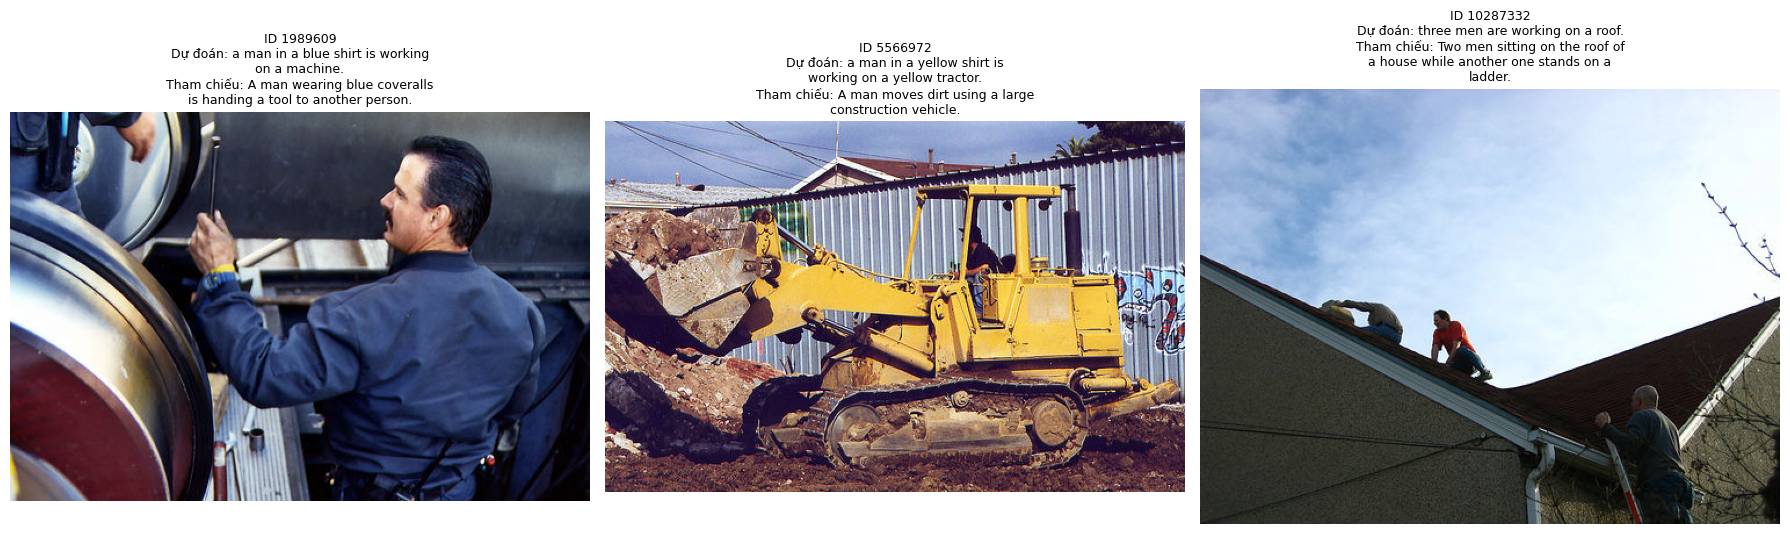

Result JSON            : /kaggle/working/F30K_T3S3_HeldOut_Test_OneTime/F30K_T3S3_HeldOut_Test_OneTime_RESULT.json
Metrics CSV            : /kaggle/working/F30K_T3S3_HeldOut_Test_OneTime/heldout_test_metrics_x100.csv
Captions JSON          : /kaggle/working/F30K_T3S3_HeldOut_Test_OneTime/heldout_test_captions.json
Qualitative PNG        : /kaggle/working/F30K_T3S3_HeldOut_Test_OneTime/heldout_test_qualitative_3_images.png
Manifest               : /kaggle/working/F30K_T3S3_HeldOut_Test_OneTime/MANIFEST.json
Final scientific gate  : PASSED AND CLOSED


In [5]:
import matplotlib.pyplot as plt
import textwrap as textwrap_module

caption_rows = []
for image_id in sorted(hypotheses):
    caption_rows.append({
        "image_id": int(image_id),
        "prediction": hypotheses[image_id][0],
        "references": TEST_REFERENCES[image_id],
    })

CAPTIONS_PATH = WORK_ROOT / "heldout_test_captions.json"
write_json(CAPTIONS_PATH, caption_rows)

METRICS_CSV = WORK_ROOT / "heldout_test_metrics_x100.csv"
with METRICS_CSV.open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["metric", "raw_value", "display_x100"])
    for name in ["BLEU_1", "BLEU_4", "METEOR", "ROUGE_L", "CIDEr_D"]:
        writer.writerow([name, raw_metrics[name], f"{metrics_x100[name]:.2f}"])
    writer.writerow(["ce_loss", raw_metrics["ce_loss"], ""])

qualitative_ids = sorted(hypotheses)[:3]
figure, axes = plt.subplots(1, 3, figsize=(18, 6))
for axis, image_id in zip(axes, qualitative_ids):
    with Image.open(IMAGE_BY_NAME[TEST_FILENAMES[image_id]]) as image:
        axis.imshow(image.convert("RGB"))
    axis.axis("off")
    prediction = textwrap_module.fill(
        "Dự đoán: " + hypotheses[image_id][0], width=42
    )
    reference = textwrap_module.fill(
        "Tham chiếu: " + TEST_REFERENCES[image_id][0], width=42
    )
    axis.set_title(
        f"ID {image_id}\n{prediction}\n{reference}",
        fontsize=9,
    )
figure.tight_layout()
QUALITATIVE_PATH = WORK_ROOT / "heldout_test_qualitative_3_images.png"
figure.savefig(QUALITATIVE_PATH, dpi=180, bbox_inches="tight")
plt.show()
plt.close(figure)

RESULT_PATH = WORK_ROOT / f"{EXPERIMENT_ID}_RESULT.json"
result = {
    "schema_version": "f30k_heldout_test_one_time_v1",
    "created_at_utc": now_utc(),
    "status": "complete_locked_no_further_test_access",
    "experiment_id": EXPERIMENT_ID,
    "dataset": "Flickr30k Karpathy Test",
    "test_image_count": 1000,
    "test_reference_count": sum(map(len, TEST_REFERENCES.values())),
    "selected_pair": selected["pair_id"],
    "method": selected["method"],
    "deployment_seed": SEED,
    "checkpoint_sha256": EXPECTED_CHECKPOINT_SHA,
    "best_validation_epoch": selected["deployment_best_epoch"],
    "decoding": {
        "beam_size": 3,
        "length_penalty": 0.7,
        "max_generated_tokens": 30,
    },
    "metrics_raw": raw_metrics,
    "metrics_x100_rounded_2dp": metrics_x100,
    "elapsed_seconds": elapsed_seconds,
    "held_out_test_authorization_consumed": True,
    "held_out_test_authorization_remaining": 0,
    "test_set_status": "opened_once_then_locked",
    "post_test_retraining_allowed": False,
    "post_test_reselection_allowed": False,
    "post_test_method_or_threshold_change_allowed": False,
    "next_phase_authorized": "F30K_Final_Report_Only",
}
write_json(RESULT_PATH, result)

artifact_paths = [
    RESULT_PATH,
    CAPTIONS_PATH,
    METRICS_CSV,
    QUALITATIVE_PATH,
]
manifest = {
    "schema_version": "f30k_heldout_manifest_v1",
    "created_at_utc": now_utc(),
    "artifact_count": len(artifact_paths),
    "artifacts": [
        {
            "relative_path": path.relative_to(WORK_ROOT).as_posix(),
            "size_bytes": path.stat().st_size,
            "sha256": sha256(path),
        }
        for path in artifact_paths
    ],
}
MANIFEST_PATH = WORK_ROOT / "MANIFEST.json"
write_json(MANIFEST_PATH, manifest)

for row in manifest["artifacts"]:
    path = WORK_ROOT / row["relative_path"]
    assert path.stat().st_size == row["size_bytes"]
    assert sha256(path) == row["sha256"]

print("Result JSON            :", RESULT_PATH)
print("Metrics CSV            :", METRICS_CSV)
print("Captions JSON          :", CAPTIONS_PATH)
print("Qualitative PNG        :", QUALITATIVE_PATH)
print("Manifest               :", MANIFEST_PATH)
print("Final scientific gate  : PASSED AND CLOSED")
